In [1]:
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2

In [1]:
from models.model3 import Model3
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior
import pymc as pm

/Users/timeipert/PycharmProjects/generative_medieval_music_model/venvnew/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


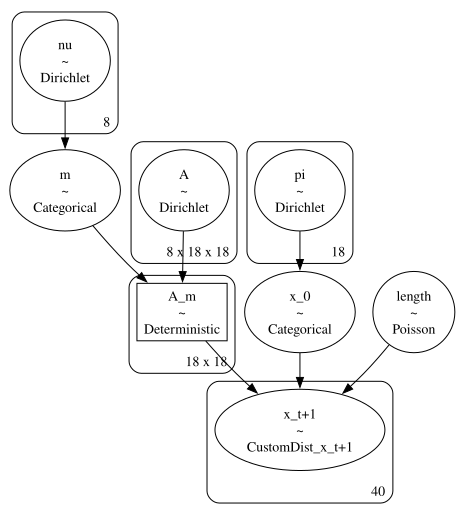

In [5]:
m3 = Model3()
m3.alpha = get_d2g_alpha(m3.V)

beta = TransitionPrior(m3.V)

beta.prefer_small_intervals(5,1)
beta.prefer_low_register(1,2,2)
beta.penalize_repeated_notes(0.3)
beta.offset(2)
m3.beta = beta.get_beta()
m3.build_model()
pm.model_to_graphviz(m3.model)

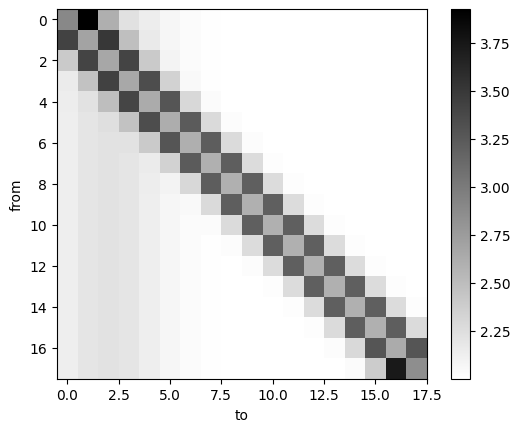

In [4]:
import models.model_utils as u
u.plot_heatmap(m3.beta)

In [5]:
#samples = m2.prior_predict(1)
#m2.show_melody(samples[0])

In [6]:
#samples

In [7]:
#import models.model_utils as u

#u.plot_heatmap(samples[0]["A_0"].sel(chain=0,draw=0).to_numpy())


In [8]:

#u.plot_heatmap(samples[0]["A_m"].sel(chain=0,draw=0).to_numpy())

In [9]:
import importlib
import analysis.compare_dist_of_intv as compare
import pandas as pd
importlib.reload(compare)

GS = pd.read_csv("data/data_gs.csv")
GS = GS[["volpiano_pitches", "modus"]].dropna()
data = GS[GS["modus"].isin(["1","2","3","4","5","6","7","8"])]
#data["modus"] = data["modus"].apply(lambda x: int(x)-1) # Index 0
data

,volpiano_pitches,modus
0,gghjhghhggkklhgfghhghkjkhkkkklhhghgkkhjggffhkj...,8
1,hhhghgeghghjhghghjhghkjkjkjhhjkjkjhjjhghjklkkj...,2
3,hgfghgegffedfghgfghgegfffehghgghhhghghgefgffdf...,4
4,cdddfddcddfgffffddefdcdacffefdddfddcddfgfffgff...,2
5,gjhhhhkhkkhgjghjhhhkhklmkjhhgjhgggfhghhfghkkhg...,2
...,...,...
154,kklkhhhggggjhhgggfghhghfffhghfhghghkkkkkgfgghg...,5
155,ddeddffffghfddfefefddddeddfefgdedccefffdgfghgg...,2
156,ggfffdeccdffghkhhgghfgkjjjjhgghghjkghffhkkkjkh...,8
157,dffgfffffghhfgfedgffgfffhfghkklmnkkhklkkkkhkhj...,5


In [10]:
data.modus.value_counts()

modus
2    22
1    22
8    21
5    20
4    14
6    13
3    11
7    11
Name: count, dtype: int64

In [11]:
raw_sequences = data["volpiano_pitches"].tolist()
    
raw_m = None
if "modus" in data.columns and data["modus"].notna().any():
    raw_m = data["modus"].astype(int).tolist()

trace = m3.fit_from_raw(
        raw_sequences=raw_sequences,
        raw_m=raw_m,
        draws=3000,
        tune=2000,
        backup="samples/model3_test_4.nc"
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, A, pi]


Output()

Sampling 4 chains for 2_000 tune and 3_000 draw iterations (8_000 + 12_000 draws total) took 6630 seconds.
There were 1858 divergences after tuning. Increase `target_accept` or reparameterize.


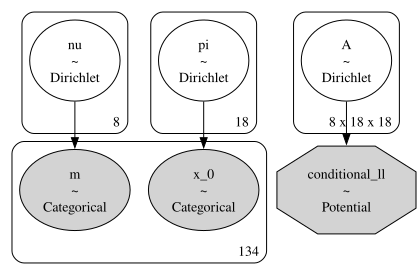

In [12]:
pm.model_to_graphviz(m3.model)

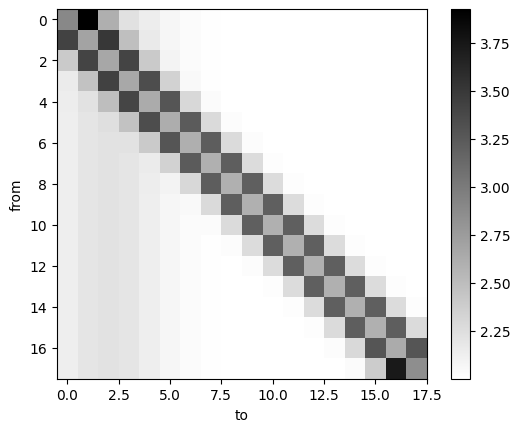

[0.01 0.01 0.01 1.   1.   1.   1.   0.01 0.01 0.01 0.01 0.01 0.01 0.01
 0.01 0.01 0.01 0.01]


In [13]:
import models.model_utils as u
u.plot_heatmap(m3.beta)
print(m3.alpha)

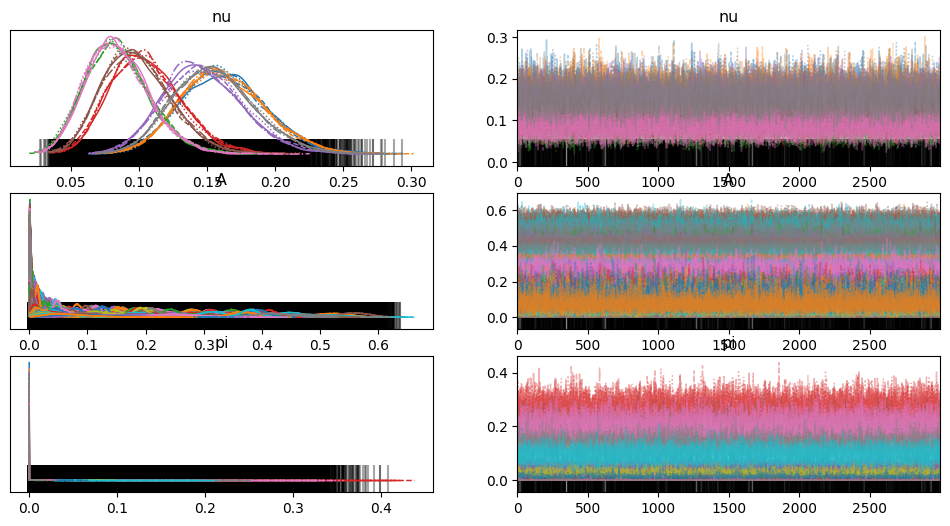

In [14]:
import arviz as az
az.plot_trace(trace, compact=True);

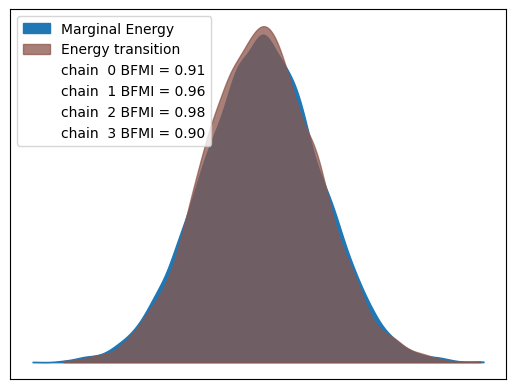

In [15]:
az.plot_energy(trace);

In [16]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

def _plot_single_heatmap(ax, matrix, alphabet, mode_index):
    sns.heatmap(
        matrix,
        xticklabels=alphabet,
        yticklabels=alphabet,
        cmap="binary",
        annot=False,
        ax=ax,
        cbar=False
    )
    ax.set_title(f"Mode {mode_index}")
    ax.set_xlabel("To Pitch")
    ax.set_ylabel("From Pitch")

def plot_posterior_matrices(trace, model, matrix_name="A"):
    posterior_mean = trace.posterior[matrix_name].mean(dim=["chain", "draw"]).values
    
    num_modes = posterior_mean.shape[0]
    cols = 4
    rows = math.ceil(num_modes / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    axes = axes.flatten()
    
    for i in range(num_modes):
        _plot_single_heatmap(axes[i], posterior_mean[i], model.alphabet, i)
        
    for j in range(num_modes, len(axes)):
        axes[j].set_visible(False)
        
    plt.tight_layout()
    plt.show()

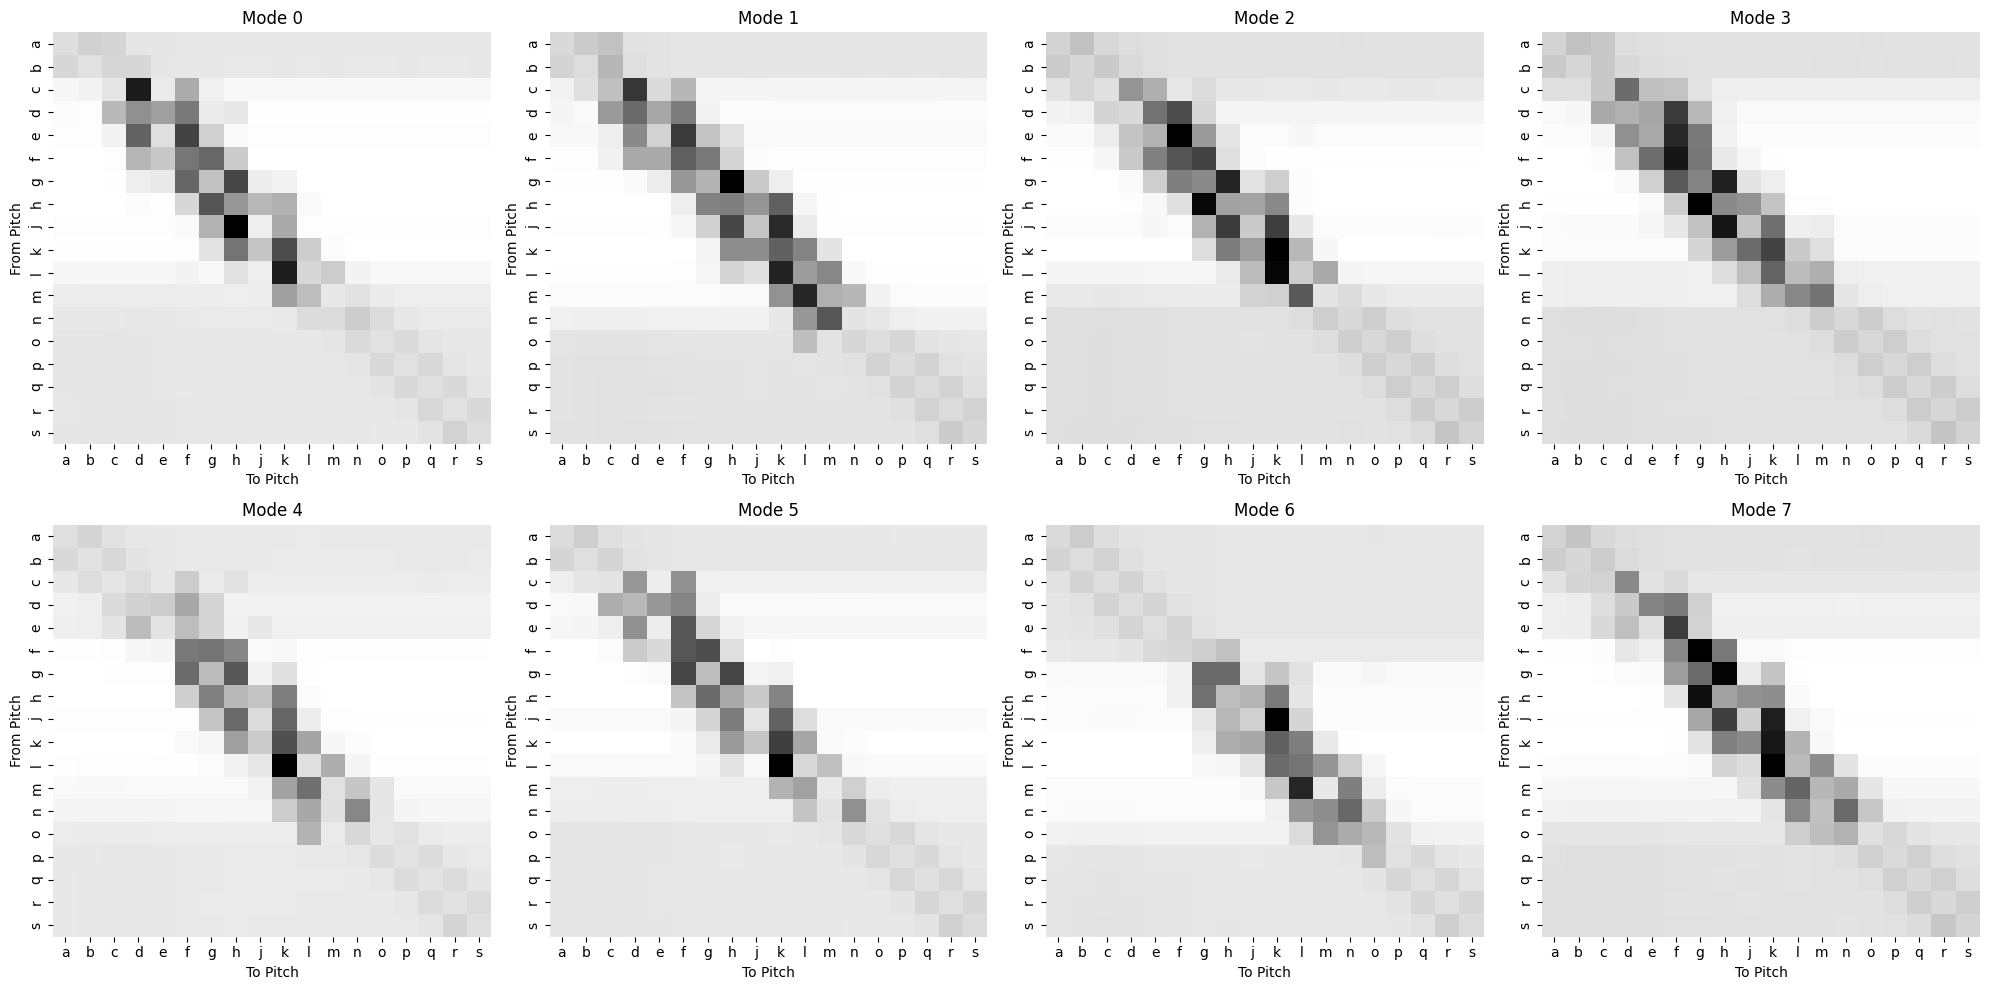

In [17]:
plot_posterior_matrices(trace, m3)

In [18]:
import analysis.visualise_posterior as vp

In [19]:
vp.plot_transition_matrix_posterior(m2.trace, "A_0")

NameError: name 'm2' is not defined